In [1]:
import pandas as pd
llm = pd.read_csv("./data/llm_without_chunks.csv")
llm

C:\Users\Asus\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,their_score_planning,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.923894,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.007498,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.530319,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.999981,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.001134,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.000004,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000116,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000207,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003473,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# split data to val,test

In [4]:
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score
f1_list_print = []
per_list_print = []
rec_list_print = []
th = [0.2,0.4,0.6,0.8]
from sklearn.model_selection import train_test_split
for t in th:
    llm['binary'] = (llm['overall_ai_score'] >= t).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['Our_work'], test_size=0.3, random_state=4)
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {t}: {optimal_threshold:.3f}")
    print("-------")
    
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")

Optimal threshold (val) 0.2: 0.011
-------
Confusion Matrix:
[[179  16]
 [ 11  70]]
Precision: 0.813953488372093
Recall: 0.8641975308641975
Accuracy: 0.9021739130434783
F1 Score: 0.8383233532934131
Optimal threshold (val) 0.4: 0.011
-------
Confusion Matrix:
[[182  30]
 [  8  56]]
Precision: 0.6511627906976745
Recall: 0.875
Accuracy: 0.8623188405797102
F1 Score: 0.7466666666666667
Optimal threshold (val) 0.6: 0.030
-------
Confusion Matrix:
[[226  15]
 [ 17  18]]
Precision: 0.5454545454545454
Recall: 0.5142857142857142
Accuracy: 0.8840579710144928
F1 Score: 0.5294117647058824
Optimal threshold (val) 0.8: 0.030
-------
Confusion Matrix:
[[233  16]
 [ 10  17]]
Precision: 0.5151515151515151
Recall: 0.6296296296296297
Accuracy: 0.9057971014492754
F1 Score: 0.5666666666666667


In [5]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.8383233532934131, 0.7466666666666667, 0.5294117647058824, 0.5666666666666667]
[0.813953488372093, 0.6511627906976745, 0.5454545454545454, 0.5151515151515151]
[0.8641975308641975, 0.875, 0.5142857142857142, 0.6296296296296297]


In [4]:
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']

In [15]:
their_work_binary_score = []
for id in llm['patent_id']:
    n = 0
    for name in name_groups:
        if (llm[llm['patent_id']==id][f'their_score_{name}'].iloc[0] > 0.928) == True:
            n=1
            break
    their_work_binary_score.append(n)

In [16]:
llm['their_work_binary_score'] = their_work_binary_score

In [17]:

f1_list_print = []
per_list_print = []
rec_list_print = []
th = [0.2,0.4,0.6,0.8]
from sklearn.model_selection import train_test_split
for t in th:
    llm['binary'] = (llm['overall_ai_score'] >= t).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['their_work_binary_score'], test_size=0.3, random_state=4)
    
    y_true = y_true_test
    y_pred = y_scores_test

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print("------")

Confusion Matrix:
[[160  35]
 [  1  80]]
Precision: 0.6956521739130435
Recall: 0.9876543209876543
Accuracy: 0.8695652173913043
F1 Score: 0.8163265306122449
------
Confusion Matrix:
[[160  52]
 [  1  63]]
Precision: 0.5478260869565217
Recall: 0.984375
Accuracy: 0.8079710144927537
F1 Score: 0.7039106145251397
------
Confusion Matrix:
[[161  80]
 [  0  35]]
Precision: 0.30434782608695654
Recall: 1.0
Accuracy: 0.7101449275362319
F1 Score: 0.4666666666666667
------
Confusion Matrix:
[[161  88]
 [  0  27]]
Precision: 0.23478260869565218
Recall: 1.0
Accuracy: 0.6811594202898551
F1 Score: 0.38028169014084506
------


In [18]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.8163265306122449, 0.7039106145251397, 0.4666666666666667, 0.38028169014084506]
[0.6956521739130435, 0.5478260869565217, 0.30434782608695654, 0.23478260869565218]
[0.9876543209876543, 0.984375, 1.0, 1.0]


### subgropups(our)

In [7]:
#0.4
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.4).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'our_score_{name}'], test_size=0.3, random_state=4)
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')

Optimal threshold (val) ml: 0.017
-------
Confusion Matrix:
[[186  26]
 [ 13  51]]
Precision: 0.6623376623376623
Recall: 0.796875
Accuracy: 0.8586956521739131
F1 Score: 0.723404255319149
-------
Optimal threshold (val) evo: 0.007
-------
Confusion Matrix:
[[158  54]
 [ 18  46]]
Precision: 0.46
Recall: 0.71875
Accuracy: 0.7391304347826086
F1 Score: 0.5609756097560976
-------
Optimal threshold (val) nlp: 0.006
-------
Confusion Matrix:
[[157  55]
 [ 21  43]]
Precision: 0.4387755102040816
Recall: 0.671875
Accuracy: 0.7246376811594203
F1 Score: 0.5308641975308642
-------
Optimal threshold (val) speech: 0.002
-------
Confusion Matrix:
[[150  62]
 [ 11  53]]
Precision: 0.4608695652173913
Recall: 0.828125
Accuracy: 0.7355072463768116
F1 Score: 0.5921787709497207
-------
Optimal threshold (val) vision: 0.006
-------
Confusion Matrix:
[[172  40]
 [ 30  34]]
Precision: 0.4594594594594595
Recall: 0.53125
Accuracy: 0.7463768115942029
F1 Score: 0.4927536231884058
-------
Optimal threshold (val) har

In [8]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.723404255319149, 0.5609756097560976, 0.5308641975308642, 0.5921787709497207, 0.4927536231884058, 0.68, 0.7354838709677419, 0.3987138263665595]
[0.6623376623376623, 0.46, 0.4387755102040816, 0.4608695652173913, 0.4594594594594595, 0.5930232558139535, 0.6263736263736264, 0.25101214574898784]
[0.796875, 0.71875, 0.671875, 0.828125, 0.53125, 0.796875, 0.890625, 0.96875]


In [9]:
#0.6
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.6).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'our_score_{name}'], test_size=0.3, random_state=4)
    #-------------
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')
    #---------
    

Optimal threshold (val) ml: 0.028
-------
Confusion Matrix:
[[223  18]
 [  9  26]]
Precision: 0.5909090909090909
Recall: 0.7428571428571429
Accuracy: 0.9021739130434783
F1 Score: 0.6582278481012658
-------
Optimal threshold (val) evo: 0.011
-------
Confusion Matrix:
[[197  44]
 [ 11  24]]
Precision: 0.35294117647058826
Recall: 0.6857142857142857
Accuracy: 0.8007246376811594
F1 Score: 0.46601941747572817
-------
Optimal threshold (val) nlp: 0.003
-------
Confusion Matrix:
[[108 133]
 [  9  26]]
Precision: 0.16352201257861634
Recall: 0.7428571428571429
Accuracy: 0.4855072463768116
F1 Score: 0.26804123711340205
-------
Optimal threshold (val) speech: 0.002
-------
Confusion Matrix:
[[147  94]
 [  8  27]]
Precision: 0.2231404958677686
Recall: 0.7714285714285715
Accuracy: 0.6304347826086957
F1 Score: 0.34615384615384615
-------
Optimal threshold (val) vision: 0.003
-------
Confusion Matrix:
[[ 92 149]
 [  6  29]]
Precision: 0.16292134831460675
Recall: 0.8285714285714286
Accuracy: 0.43840579

In [10]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.6582278481012658, 0.46601941747572817, 0.26804123711340205, 0.34615384615384615, 0.27230046948356806, 0.5882352941176471, 0.5370370370370371, 0.24113475177304963]
[0.5909090909090909, 0.35294117647058826, 0.16352201257861634, 0.2231404958677686, 0.16292134831460675, 0.44776119402985076, 0.3972602739726027, 0.13765182186234817]
[0.7428571428571429, 0.6857142857142857, 0.7428571428571429, 0.7714285714285715, 0.8285714285714286, 0.8571428571428571, 0.8285714285714286, 0.9714285714285714]


### subgroups(their)

In [4]:
#0.4
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.4).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'their_score_{name}'], test_size=0.3, random_state=4)
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')

Optimal threshold (val) ml: 0.928
-------
Confusion Matrix:
[[196  16]
 [ 17  47]]
Precision: 0.746031746031746
Recall: 0.734375
Accuracy: 0.8804347826086957
F1 Score: 0.7401574803149606
-------
Optimal threshold (val) evo: 0.000
-------
Confusion Matrix:
[[  3 209]
 [  1  63]]
Precision: 0.23161764705882354
Recall: 0.984375
Accuracy: 0.2391304347826087
F1 Score: 0.375
-------
Optimal threshold (val) nlp: 0.051
-------
Confusion Matrix:
[[189  23]
 [ 34  30]]
Precision: 0.5660377358490566
Recall: 0.46875
Accuracy: 0.7934782608695652
F1 Score: 0.5128205128205128
-------
Optimal threshold (val) speech: 0.001
-------
Confusion Matrix:
[[163  49]
 [ 22  42]]
Precision: 0.46153846153846156
Recall: 0.65625
Accuracy: 0.7427536231884058
F1 Score: 0.5419354838709678
-------
Optimal threshold (val) vision: 0.052
-------
Confusion Matrix:
[[189  23]
 [ 34  30]]
Precision: 0.5660377358490566
Recall: 0.46875
Accuracy: 0.7934782608695652
F1 Score: 0.5128205128205128
-------
Optimal threshold (val) h

In [5]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.7401574803149606, 0.375, 0.5128205128205128, 0.5419354838709678, 0.5128205128205128, 0.6625766871165644, 0.5109489051094891, 0.6125]
[0.746031746031746, 0.23161764705882354, 0.5660377358490566, 0.46153846153846156, 0.5660377358490566, 0.5454545454545454, 0.4794520547945205, 0.5104166666666666]
[0.734375, 0.984375, 0.46875, 0.65625, 0.46875, 0.84375, 0.546875, 0.765625]


In [13]:
#0.6
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.6).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'their_score_{name}'], test_size=0.3, random_state=4)
    #-------------
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')
    #---------
    

Optimal threshold (val) ml: 1.000
-------
Confusion Matrix:
[[231  10]
 [ 12  23]]
Precision: 0.696969696969697
Recall: 0.6571428571428571
Accuracy: 0.9202898550724637
F1 Score: 0.6764705882352942
-------
Optimal threshold (val) evo: 0.004
-------
Confusion Matrix:
[[198  43]
 [ 29   6]]
Precision: 0.12244897959183673
Recall: 0.17142857142857143
Accuracy: 0.7391304347826086
F1 Score: 0.14285714285714285
-------
Optimal threshold (val) nlp: 0.051
-------
Confusion Matrix:
[[203  38]
 [ 20  15]]
Precision: 0.2830188679245283
Recall: 0.42857142857142855
Accuracy: 0.7898550724637681
F1 Score: 0.3409090909090909
-------
Optimal threshold (val) speech: 0.001
-------
Confusion Matrix:
[[193  48]
 [ 20  15]]
Precision: 0.23809523809523808
Recall: 0.42857142857142855
Accuracy: 0.7536231884057971
F1 Score: 0.30612244897959184
-------
Optimal threshold (val) vision: 0.052
-------
Confusion Matrix:
[[207  34]
 [ 16  19]]
Precision: 0.3584905660377358
Recall: 0.5428571428571428
Accuracy: 0.81884057

In [14]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.6764705882352942, 0.14285714285714285, 0.3409090909090909, 0.30612244897959184, 0.4318181818181818, 0.5128205128205128, 0.3387096774193548, 0.37168141592920356]
[0.696969696969697, 0.12244897959183673, 0.2830188679245283, 0.23809523809523808, 0.3584905660377358, 0.36585365853658536, 0.23595505617977527, 0.2692307692307692]
[0.6571428571428571, 0.17142857142857143, 0.42857142857142855, 0.42857142857142855, 0.5428571428571428, 0.8571428571428571, 0.6, 0.6]


### plots

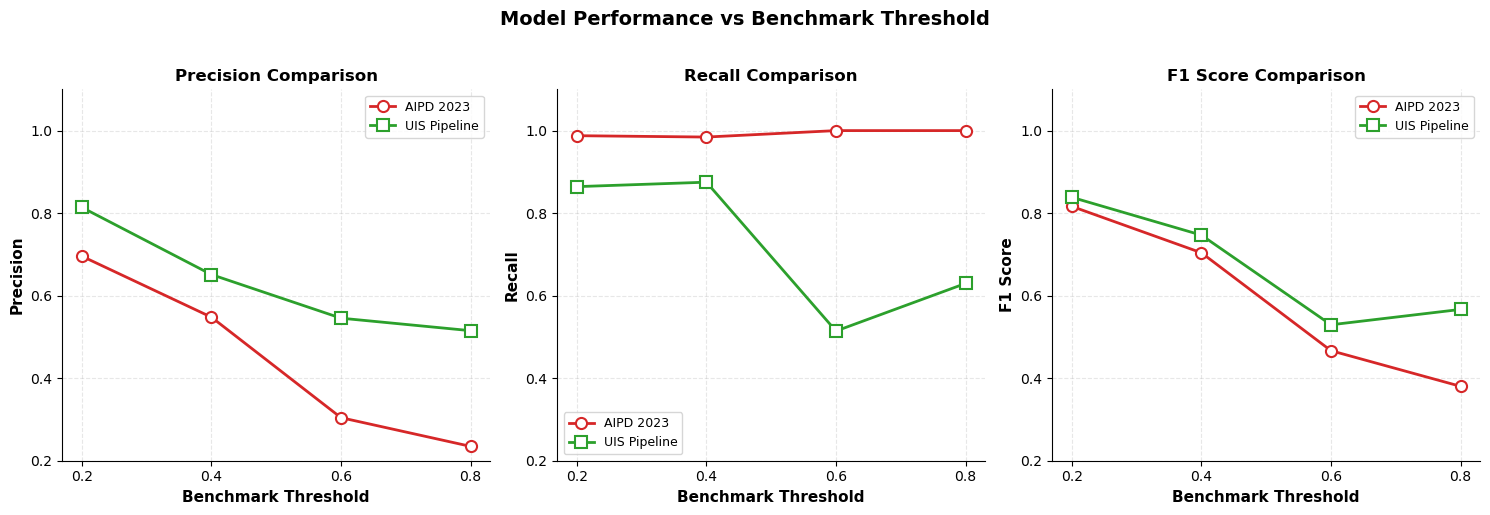

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

thresholds = [0.2, 0.4, 0.6, 0.8]




# Their metrics
their_precision = [0.6956521739130435, 0.5478260869565217, 0.30434782608695654, 0.23478260869565218]
their_recall = [0.9876543209876543, 0.984375, 1.0, 1.0]
their_f1 = [0.8163265306122449, 0.7039106145251397, 0.4666666666666667, 0.38028169014084506]


    
    
# Our metrics
our_precision = [0.813953488372093, 0.6511627906976745, 0.5454545454545454, 0.5151515151515151]
our_recall = [0.8641975308641975, 0.875, 0.5142857142857142, 0.6296296296296297]
our_f1 = [0.8383233532934131, 0.7466666666666667, 0.5294117647058824, 0.5666666666666667]

# Create 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Model Performance vs Benchmark Threshold', fontsize=14, fontweight='bold', y=1.02)

metrics = [
    ('Precision', their_precision, our_precision, '#d62728', '#2ca02c', [0.2, 1.1]),
    ('Recall', their_recall, our_recall, '#d62728', '#2ca02c', [0.2, 1.1]),
    ('F1 Score', their_f1, our_f1, '#d62728', '#2ca02c', [0.2, 1.1])
]

for ax, (title, their_vals, our_vals, color_their, color_our, ylim) in zip(axes, metrics):
    ax.plot(thresholds, their_vals, 'o-', linewidth=2, markersize=8, 
            color=color_their, label='AIPD 2023', markerfacecolor='white', markeredgewidth=1.5)
    ax.plot(thresholds, our_vals, 's-', linewidth=2, markersize=8, 
            color=color_our, label='UIS Pipeline', markerfacecolor='white', markeredgewidth=1.5)
    
    ax.set_xlabel('Benchmark Threshold', fontsize=11, fontweight='bold')
    ax.set_ylabel(title, fontsize=11, fontweight='bold')
    ax.set_title(f'{title} Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(thresholds)
    ax.set_ylim(ylim)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='best', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

fig.savefig('find_threshold_500_split.png', dpi=300, bbox_inches='tight')

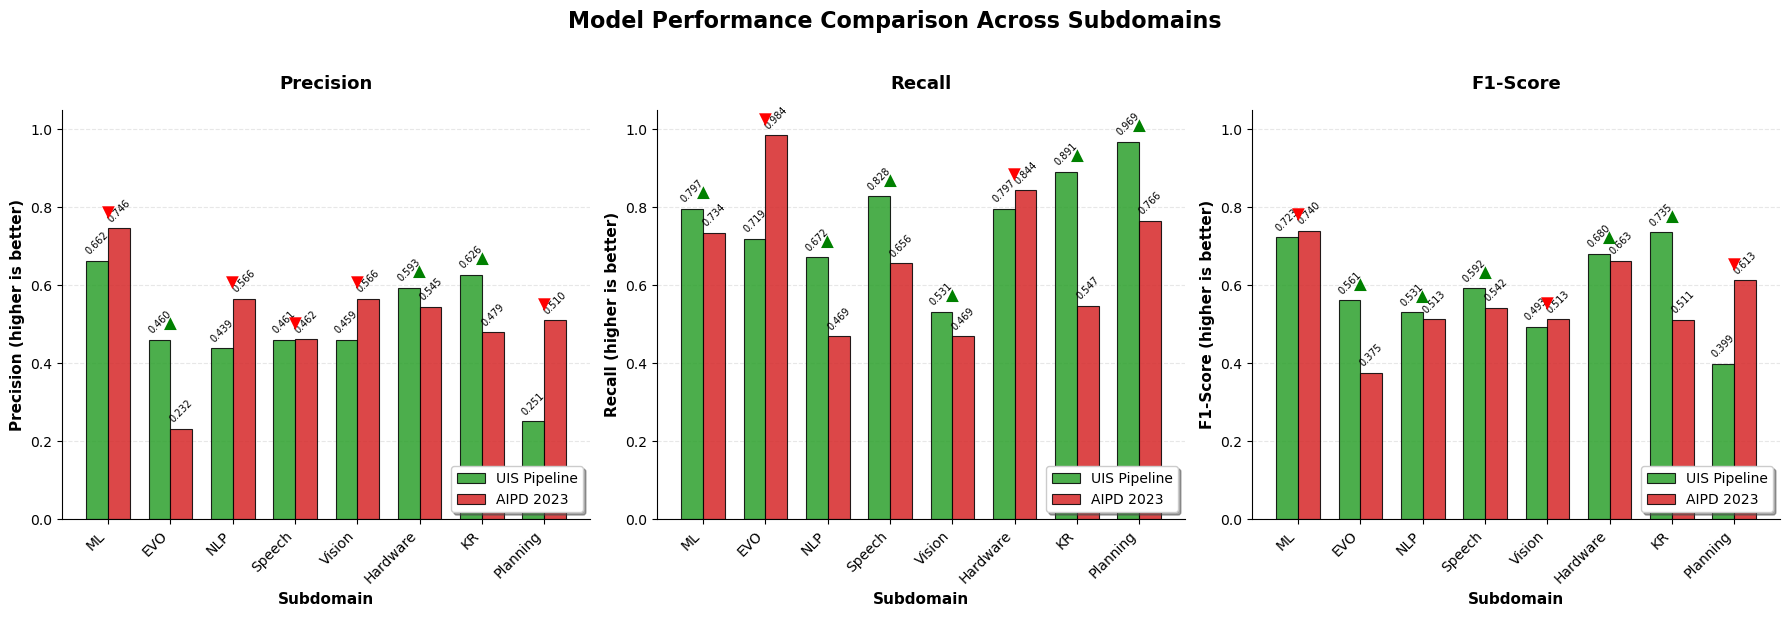

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Data
subdomains = ['ML', 'EVO', 'NLP', 'Speech', 'Vision', 'Hardware', 'KR', 'Planning']

# Threshold 0.4 metrics
their_precision_4 = [0.746031746031746, 0.23161764705882354, 0.5660377358490566, 0.46153846153846156, 0.5660377358490566, 0.5454545454545454, 0.4794520547945205, 0.5104166666666666]
their_recall_4 = [0.734375, 0.984375, 0.46875, 0.65625, 0.46875, 0.84375, 0.546875, 0.765625] 
their_f1_4 = [0.7401574803149606, 0.375, 0.5128205128205128, 0.5419354838709678, 0.5128205128205128, 0.6625766871165644, 0.5109489051094891, 0.6125]

our_precision_4 = [0.6623376623376623, 0.46, 0.4387755102040816, 0.4608695652173913, 0.4594594594594595, 0.5930232558139535, 0.6263736263736264, 0.25101214574898784]
our_recall_4 = [0.796875, 0.71875, 0.671875, 0.828125, 0.53125, 0.796875, 0.890625, 0.96875]
our_f1_4 = [0.723404255319149, 0.5609756097560976, 0.5308641975308642, 0.5921787709497207, 0.4927536231884058, 0.68, 0.7354838709677419, 0.3987138263665595]


# Setup
x = np.arange(len(subdomains))
width = 0.35

# Define metrics for plotting
metrics = [
    ('Precision', our_precision_4, their_precision_4),
    ('Recall', our_recall_4, their_recall_4),
    ('F1-Score', our_f1_4, their_f1_4)
]

# Create figure with 1 row and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model Performance Comparison Across Subdomains', 
             fontsize=16, fontweight='bold', y=1.02)

colors = ['#2ca02c', '#d62728']  # Green for UIS Pipeline, Red for AIPD 2023

# Create plots for each metric
for col_idx, (metric_name, our_vals, their_vals) in enumerate(metrics):
    ax = axes[col_idx]  # Access 1D array directly
    
    # Bars
    bars1 = ax.bar(x - width/2, our_vals, width, label='UIS Pipeline', 
                   color=colors[0], edgecolor='black', linewidth=0.8, alpha=0.85)
    bars2 = ax.bar(x + width/2, their_vals, width, label='AIPD 2023', 
                   color=colors[1], edgecolor='black', linewidth=0.8, alpha=0.85)
    
    # Value labels on bars
    for bar in bars1:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=7, rotation=45)
    
    for bar in bars2:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=7, rotation=45)
    
    # Labels and formatting
    ax.set_ylabel(f'{metric_name} (higher is better)', fontsize=11, fontweight='bold')
    ax.set_xlabel('Subdomain', fontsize=11, fontweight='bold')
    ax.set_title(f'{metric_name}', fontsize=13, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(subdomains, fontsize=10, rotation=45, ha='right')
    ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right', frameon=True, fancybox=True, shadow=True)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Highlight areas where we are better
    for i, (our, their) in enumerate(zip(our_vals, their_vals)):
        if our > their:
            ax.annotate('▲', xy=(x[i], max(our, their) + 0.03), 
                       ha='center', fontsize=12, color='green', fontweight='bold')
        elif our < their:
            ax.annotate('▼', xy=(x[i], max(our, their) + 0.03), 
                       ha='center', fontsize=12, color='red', fontweight='bold')

plt.tight_layout()
plt.show()

# Save figure
fig.savefig('precision_recall_f1_comparison_threshold_04.png', dpi=300, bbox_inches='tight')

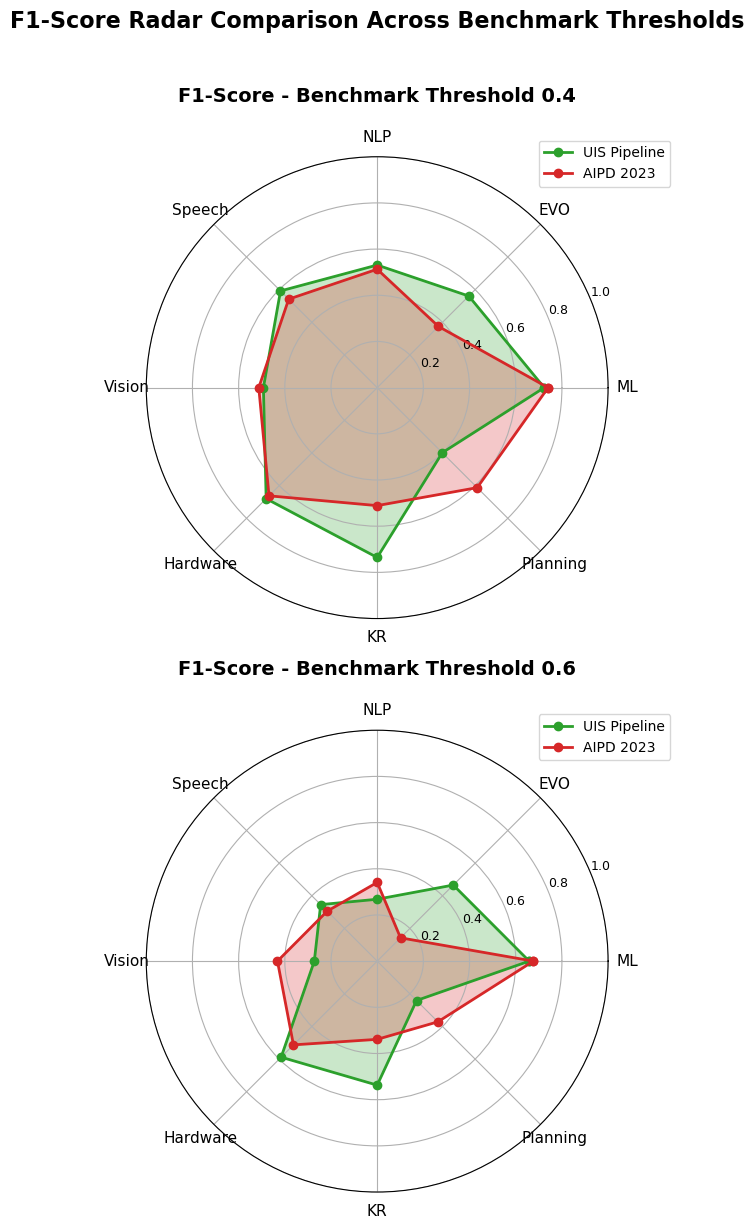

In [5]:
import matplotlib.pyplot as plt
import numpy as np

subdomains = ['ML', 'EVO', 'NLP', 'Speech', 'Vision', 'Hardware', 'KR', 'Planning']

# Threshold 0.4 F1 scores
their_f1_4 = [0.7401574803149606, 0.375, 0.5128205128205128, 0.5419354838709678, 0.5128205128205128, 0.6625766871165644, 0.5109489051094891, 0.6125]
our_f1_4 = [0.723404255319149, 0.5609756097560976, 0.5308641975308642, 0.5921787709497207, 0.4927536231884058, 0.68, 0.7354838709677419, 0.3987138263665595]

# Threshold 0.6 F1 scores
their_f1_6 = [0.6764705882352942, 0.14285714285714285, 0.3409090909090909, 0.30612244897959184, 0.4318181818181818, 0.5128205128205128, 0.3387096774193548, 0.37168141592920356]
our_f1_6 = [0.6582278481012658, 0.46601941747572817, 0.26804123711340205, 0.34615384615384615, 0.27230046948356806, 0.5882352941176471, 0.5370370370370371, 0.24113475177304963]

# Radar chart setup
angles = np.linspace(0, 2 * np.pi, len(subdomains), endpoint=False).tolist()
angles += angles[:1]  # close the loop

# Create figure with 2 subplots stacked vertically (top and bottom)
fig, axes = plt.subplots(2, 1, figsize=(10, 12), subplot_kw={'projection': 'polar'})

# Plot for Threshold 0.4 (Top)
our_f1_4_closed = our_f1_4 + our_f1_4[:1]
their_f1_4_closed = their_f1_4 + their_f1_4[:1]

axes[0].plot(angles, our_f1_4_closed, 'o-', linewidth=2, label='UIS Pipeline', color='#2ca02c')
axes[0].fill(angles, our_f1_4_closed, alpha=0.25, color='#2ca02c')
axes[0].plot(angles, their_f1_4_closed, 'o-', linewidth=2, label='AIPD 2023', color='#d62728')
axes[0].fill(angles, their_f1_4_closed, alpha=0.25, color='#d62728')

axes[0].set_xticks(angles[:-1])
axes[0].set_xticklabels(subdomains, fontsize=11)
axes[0].set_ylim(0, 1)
axes[0].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
axes[0].set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)
axes[0].set_title('F1-Score - Benchmark Threshold 0.4', fontsize=14, fontweight='bold', pad=20)
axes[0].legend(loc='upper right', bbox_to_anchor=(1.15, 1.05))

# Plot for Threshold 0.6 (Bottom)
our_f1_6_closed = our_f1_6 + our_f1_6[:1]
their_f1_6_closed = their_f1_6 + their_f1_6[:1]

axes[1].plot(angles, our_f1_6_closed, 'o-', linewidth=2, label='UIS Pipeline', color='#2ca02c')
axes[1].fill(angles, our_f1_6_closed, alpha=0.25, color='#2ca02c')
axes[1].plot(angles, their_f1_6_closed, 'o-', linewidth=2, label='AIPD 2023', color='#d62728')
axes[1].fill(angles, their_f1_6_closed, alpha=0.25, color='#d62728')

axes[1].set_xticks(angles[:-1])
axes[1].set_xticklabels(subdomains, fontsize=11)
axes[1].set_ylim(0, 1)
axes[1].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
axes[1].set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)
axes[1].set_title('F1-Score - Benchmark Threshold 0.6', fontsize=14, fontweight='bold', pad=20)
axes[1].legend(loc='upper right', bbox_to_anchor=(1.15, 1.05))

# Add overall title
fig.suptitle('F1-Score Radar Comparison Across Benchmark Thresholds', fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

# Save figure
fig.savefig('f1_comparison_both_thresholds_500_split.png', dpi=300, bbox_inches='tight')

# confident interval

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
llm['binary'] = (llm['overall_ai_score'] >= 0.4).astype(int)
y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['Our_work'], test_size=0.3, random_state=4)
from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]
print(f"Optimal threshold (val) {0.4}: {optimal_threshold:.3f}")
print("-------")

binary_our = (y_scores_test >= optimal_threshold).astype(int)

# Assuming your 'predict' column contains the true values
y_true = y_true_test
y_pred1 = binary_our

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Calculate precision, recall, accuracy, and F1 score
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
# Print the results
print("Confusion Matrix:")
print(conf_matrix)
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"Accuracy: {accuracy}")
print(f"F1 Score: {f1}")

In [38]:
y_true

477    0
244    1
702    0
710    0
855    0
      ..
433    0
620    0
423    0
347    0
574    0
Name: binary, Length: 276, dtype: int32

Bootstrap Results (95% Confidence Intervals):
--------------------------------------------------
F1:
  Mean: 0.5242
  95% CI: [0.3692, 0.6667]

Precision:
  Mean: 0.5443
  95% CI: [0.3823, 0.7098]

Recall:
  Mean: 0.5124
  95% CI: [0.3243, 0.6765]



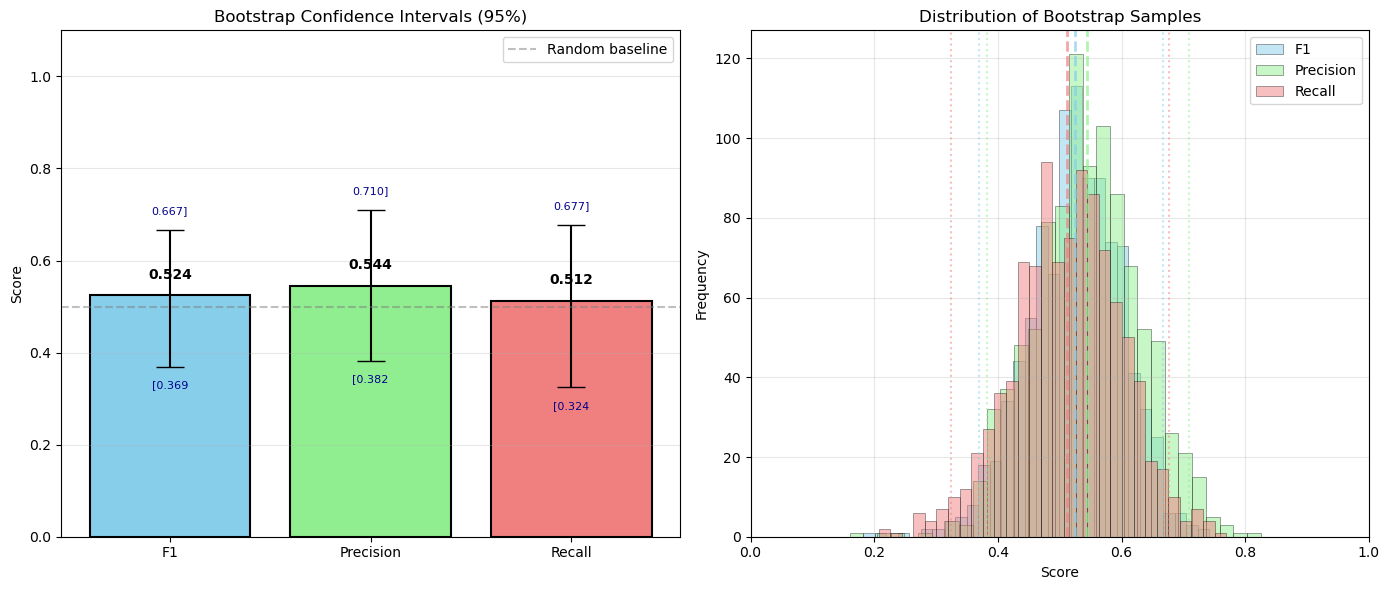

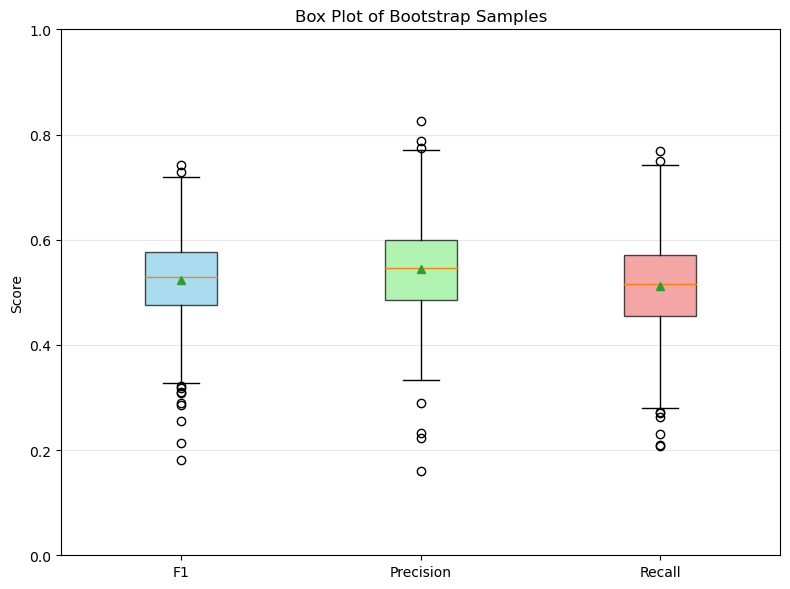


Summary Statistics:
--------------------------------------------------
F1:
  Mean: 0.5242
  Std: 0.0762
  Median: 0.5294
  95% CI: [0.3692, 0.6667]

Precision:
  Mean: 0.5443
  Std: 0.0874
  Median: 0.5455
  95% CI: [0.3823, 0.7098]

Recall:
  Mean: 0.5124
  Std: 0.0876
  Median: 0.5152
  95% CI: [0.3243, 0.6765]



In [11]:
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

def bootstrap_ci(y_true, y_pred, n_bootstraps=1000, ci=95):
    # Ensure inputs are numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    bootstrapped_f1 = []
    bootstrapped_precision = []
    bootstrapped_recall = []
    
    rng = np.random.default_rng(seed=42)  # For reproducibility
    indices = np.arange(len(y_true))
    
    for _ in range(n_bootstraps):
        # Resample indices with replacement
        boot_idx = rng.choice(indices, size=len(indices), replace=True)
        
        # Calculate metrics for this bootstrap sample
        bootstrapped_f1.append(f1_score(y_true[boot_idx], y_pred[boot_idx], average='binary'))
        bootstrapped_precision.append(precision_score(y_true[boot_idx], y_pred[boot_idx], average='binary'))
        bootstrapped_recall.append(recall_score(y_true[boot_idx], y_pred[boot_idx], average='binary'))
    
    # Calculate percentiles for the confidence interval
    lower_percentile = (100 - ci) / 2
    upper_percentile = 100 - lower_percentile
    
    metrics = {
        'f1': bootstrapped_f1, 
        'precision': bootstrapped_precision, 
        'recall': bootstrapped_recall
    }
    
    results = {}
    for name, values in metrics.items():
        lower = np.percentile(values, lower_percentile)
        upper = np.percentile(values, upper_percentile)
        mean = np.mean(values)
        results[name] = {
            'mean': mean,
            'lower': lower,
            'upper': upper,
            'values': values
        }
    
    return results

def plot_bootstrap_results(results):
    """
    Plot the bootstrap results with confidence intervals
    
    Parameters:
    results: dict returned by bootstrap_ci function
    """
    metric_names = list(results.keys())
    means = [results[metric]['mean'] for metric in metric_names]
    lower_bounds = [results[metric]['lower'] for metric in metric_names]
    upper_bounds = [results[metric]['upper'] for metric in metric_names]
    
    # Calculate errors (asymmetric error bars)
    lower_errors = [mean - lower for mean, lower in zip(means, lower_bounds)]
    upper_errors = [upper - mean for mean, upper in zip(means, upper_bounds)]
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot 1: Bar plot with error bars (confidence intervals)
    x_positions = np.arange(len(metric_names))
    
    # Correct way to specify asymmetric error bars
    ax1.bar(x_positions, means, 
            yerr=[lower_errors, upper_errors],  # [lower errors, upper errors]
            capsize=10, 
            color=['skyblue', 'lightgreen', 'lightcoral'], 
            edgecolor='black', 
            linewidth=1.5)
    ax1.set_xticks(x_positions)
    ax1.set_xticklabels([m.capitalize() for m in metric_names])
    ax1.set_ylabel('Score')
    ax1.set_title('Bootstrap Confidence Intervals (95%)')
    ax1.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random baseline')
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_ylim(0, 1.1)  # Set y-axis limits to show full range
    
    # Add value labels on top of bars
    for i, (mean, lower, upper) in enumerate(zip(means, lower_bounds, upper_bounds)):
        ax1.text(i, mean + 0.03, f'{mean:.3f}', 
                ha='center', va='bottom', fontweight='bold')
        ax1.text(i, lower - 0.03, f'[{lower:.3f}', 
                ha='center', va='top', fontsize=8, color='darkblue')
        ax1.text(i, upper + 0.03, f'{upper:.3f}]', 
                ha='center', va='bottom', fontsize=8, color='darkblue')
    
    # Plot 2: Distribution histograms
    colors = ['skyblue', 'lightgreen', 'lightcoral']
    for idx, (metric_name, color) in enumerate(zip(metric_names, colors)):
        values = results[metric_name]['values']
        ax2.hist(values, bins=30, alpha=0.5, label=metric_name.capitalize(), 
                color=color, edgecolor='black', linewidth=0.5)
        # Add vertical line for mean
        ax2.axvline(results[metric_name]['mean'], color=color, 
                   linestyle='--', linewidth=2, alpha=0.7)
        # Add vertical lines for CI bounds
        ax2.axvline(results[metric_name]['lower'], color=color, 
                   linestyle=':', linewidth=1.5, alpha=0.5)
        ax2.axvline(results[metric_name]['upper'], color=color, 
                   linestyle=':', linewidth=1.5, alpha=0.5)
    
    ax2.set_xlabel('Score')
    ax2.set_ylabel('Frequency')
    ax2.set_title('Distribution of Bootstrap Samples')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(0, 1)  # Set x-axis limits for better visualization
    
    plt.tight_layout()
    plt.show()
    
    # Additional plot: Box plot
    fig, ax3 = plt.subplots(figsize=(8, 6))
    
    data_to_plot = [results[metric]['values'] for metric in metric_names]
    box = ax3.boxplot(data_to_plot, labels=[m.capitalize() for m in metric_names],
                     patch_artist=True, showmeans=True)
    
    # Customize box colors
    colors = ['skyblue', 'lightgreen', 'lightcoral']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax3.set_ylabel('Score')
    ax3.set_title('Box Plot of Bootstrap Samples')
    ax3.grid(True, alpha=0.3, axis='y')
    ax3.set_ylim(0, 1)  # Set y-axis limits
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\nSummary Statistics:")
    print("-" * 50)
    for metric in metric_names:
        values = results[metric]['values']
        print(f"{metric.capitalize()}:")
        print(f"  Mean: {results[metric]['mean']:.4f}")
        print(f"  Std: {np.std(values):.4f}")
        print(f"  Median: {np.median(values):.4f}")
        print(f"  95% CI: [{results[metric]['lower']:.4f}, {results[metric]['upper']:.4f}]")
        print()

# Example Usage:
if __name__ == "__main__":
    
    # Calculate bootstrap confidence intervals
    results = bootstrap_ci(y_true, y_pred, n_bootstraps=1000, ci=95)
    
    # Print results
    print("Bootstrap Results (95% Confidence Intervals):")
    print("-" * 50)
    for metric, values in results.items():
        print(f"{metric.capitalize()}:")
        print(f"  Mean: {values['mean']:.4f}")
        print(f"  95% CI: [{values['lower']:.4f}, {values['upper']:.4f}]")
        print()
    
    # Plot the results
    plot_bootstrap_results(results)

In [4]:
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']

In [18]:
their_work_binary_score = []
for id in llm['patent_id']:
    n = 0
    for name in name_groups:
        if (llm[llm['patent_id']==id][f'their_score_{name}'].iloc[0] > 0.928) == True:
            n=1
            break
    their_work_binary_score.append(n)

In [19]:
llm['their_work_binary_score'] = their_work_binary_score

In [ ]:
llm['binary'] = (llm['overall_ai_score'] >= 0.6).astype(int)
y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['their_work_binary_score'], test_size=0.3, random_state=4)

y_true = y_true_test
y_pred2 = y_scores_test

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Calculate precision, recall, accuracy, and F1 score
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Print the results
print("Confusion Matrix:")
print(conf_matrix)
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"Accuracy: {accuracy}")
print(f"F1 Score: {f1}")
print("------")

Bootstrap Results (95% Confidence Intervals):
--------------------------------------------------
F1:
  Mean: 0.4687
  95% CI: [0.3660, 0.5625]

Precision:
  Mean: 0.3075
  95% CI: [0.2240, 0.3913]

Recall:
  Mean: 1.0000
  95% CI: [1.0000, 1.0000]



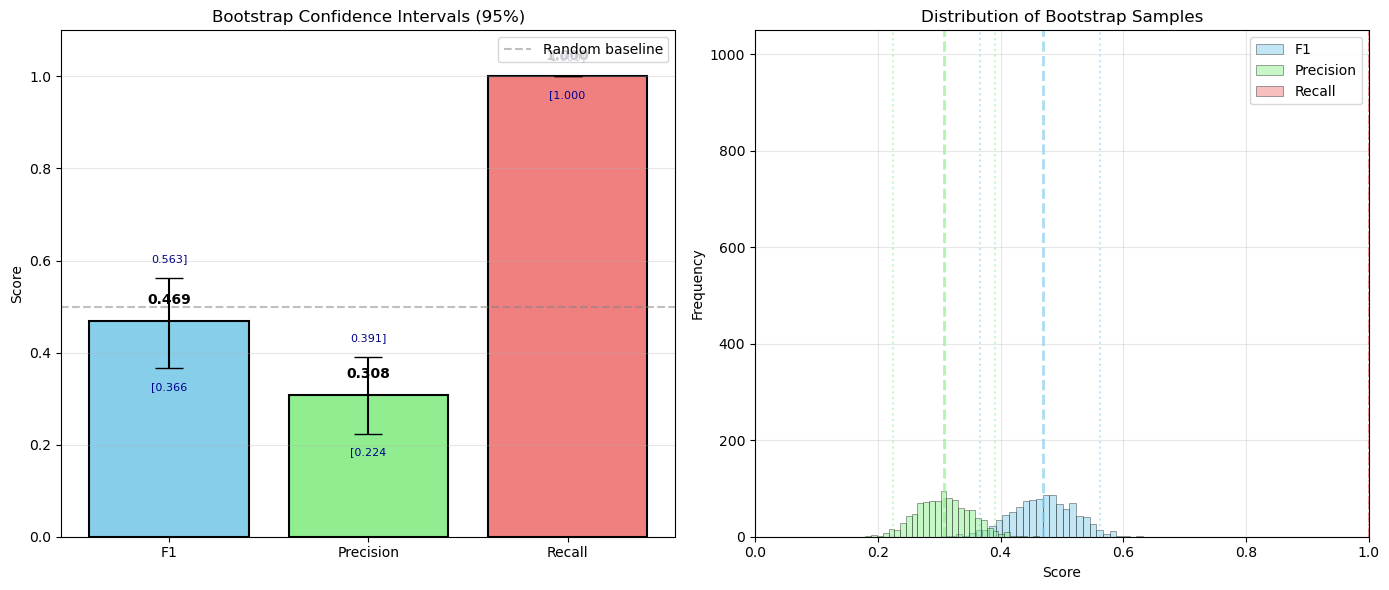

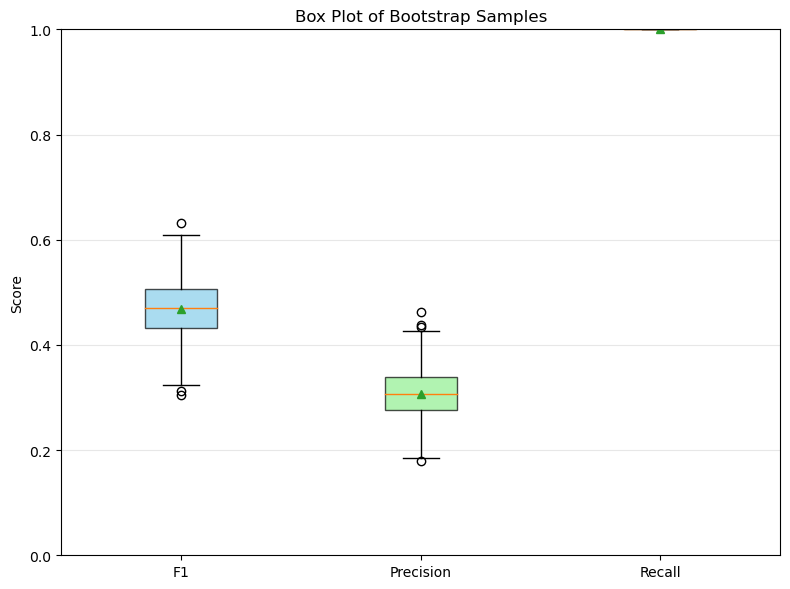


Summary Statistics:
--------------------------------------------------
F1:
  Mean: 0.4687
  Std: 0.0511
  Median: 0.4698
  95% CI: [0.3660, 0.5625]

Precision:
  Mean: 0.3075
  Std: 0.0436
  Median: 0.3070
  95% CI: [0.2240, 0.3913]

Recall:
  Mean: 1.0000
  Std: 0.0000
  Median: 1.0000
  95% CI: [1.0000, 1.0000]



In [17]:
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

def bootstrap_ci(y_true, y_pred, n_bootstraps=1000, ci=95):
    # Ensure inputs are numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    bootstrapped_f1 = []
    bootstrapped_precision = []
    bootstrapped_recall = []
    
    rng = np.random.default_rng(seed=42)  # For reproducibility
    indices = np.arange(len(y_true))
    
    for _ in range(n_bootstraps):
        # Resample indices with replacement
        boot_idx = rng.choice(indices, size=len(indices), replace=True)
        
        # Calculate metrics for this bootstrap sample
        bootstrapped_f1.append(f1_score(y_true[boot_idx], y_pred[boot_idx], average='binary'))
        bootstrapped_precision.append(precision_score(y_true[boot_idx], y_pred[boot_idx], average='binary'))
        bootstrapped_recall.append(recall_score(y_true[boot_idx], y_pred[boot_idx], average='binary'))
    
    # Calculate percentiles for the confidence interval
    lower_percentile = (100 - ci) / 2
    upper_percentile = 100 - lower_percentile
    
    metrics = {
        'f1': bootstrapped_f1, 
        'precision': bootstrapped_precision, 
        'recall': bootstrapped_recall
    }
    
    results = {}
    for name, values in metrics.items():
        lower = np.percentile(values, lower_percentile)
        upper = np.percentile(values, upper_percentile)
        mean = np.mean(values)
        results[name] = {
            'mean': mean,
            'lower': lower,
            'upper': upper,
            'values': values
        }
    
    return results

def plot_bootstrap_results(results):
    """
    Plot the bootstrap results with confidence intervals
    
    Parameters:
    results: dict returned by bootstrap_ci function
    """
    metric_names = list(results.keys())
    means = [results[metric]['mean'] for metric in metric_names]
    lower_bounds = [results[metric]['lower'] for metric in metric_names]
    upper_bounds = [results[metric]['upper'] for metric in metric_names]
    
    # Calculate errors (asymmetric error bars)
    lower_errors = [mean - lower for mean, lower in zip(means, lower_bounds)]
    upper_errors = [upper - mean for mean, upper in zip(means, upper_bounds)]
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot 1: Bar plot with error bars (confidence intervals)
    x_positions = np.arange(len(metric_names))
    
    # Correct way to specify asymmetric error bars
    ax1.bar(x_positions, means, 
            yerr=[lower_errors, upper_errors],  # [lower errors, upper errors]
            capsize=10, 
            color=['skyblue', 'lightgreen', 'lightcoral'], 
            edgecolor='black', 
            linewidth=1.5)
    ax1.set_xticks(x_positions)
    ax1.set_xticklabels([m.capitalize() for m in metric_names])
    ax1.set_ylabel('Score')
    ax1.set_title('Bootstrap Confidence Intervals (95%)')
    ax1.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random baseline')
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_ylim(0, 1.1)  # Set y-axis limits to show full range
    
    # Add value labels on top of bars
    for i, (mean, lower, upper) in enumerate(zip(means, lower_bounds, upper_bounds)):
        ax1.text(i, mean + 0.03, f'{mean:.3f}', 
                ha='center', va='bottom', fontweight='bold')
        ax1.text(i, lower - 0.03, f'[{lower:.3f}', 
                ha='center', va='top', fontsize=8, color='darkblue')
        ax1.text(i, upper + 0.03, f'{upper:.3f}]', 
                ha='center', va='bottom', fontsize=8, color='darkblue')
    
    # Plot 2: Distribution histograms
    colors = ['skyblue', 'lightgreen', 'lightcoral']
    for idx, (metric_name, color) in enumerate(zip(metric_names, colors)):
        values = results[metric_name]['values']
        ax2.hist(values, bins=30, alpha=0.5, label=metric_name.capitalize(), 
                color=color, edgecolor='black', linewidth=0.5)
        # Add vertical line for mean
        ax2.axvline(results[metric_name]['mean'], color=color, 
                   linestyle='--', linewidth=2, alpha=0.7)
        # Add vertical lines for CI bounds
        ax2.axvline(results[metric_name]['lower'], color=color, 
                   linestyle=':', linewidth=1.5, alpha=0.5)
        ax2.axvline(results[metric_name]['upper'], color=color, 
                   linestyle=':', linewidth=1.5, alpha=0.5)
    
    ax2.set_xlabel('Score')
    ax2.set_ylabel('Frequency')
    ax2.set_title('Distribution of Bootstrap Samples')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(0, 1)  # Set x-axis limits for better visualization
    
    plt.tight_layout()
    plt.show()
    
    # Additional plot: Box plot
    fig, ax3 = plt.subplots(figsize=(8, 6))
    
    data_to_plot = [results[metric]['values'] for metric in metric_names]
    box = ax3.boxplot(data_to_plot, labels=[m.capitalize() for m in metric_names],
                     patch_artist=True, showmeans=True)
    
    # Customize box colors
    colors = ['skyblue', 'lightgreen', 'lightcoral']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax3.set_ylabel('Score')
    ax3.set_title('Box Plot of Bootstrap Samples')
    ax3.grid(True, alpha=0.3, axis='y')
    ax3.set_ylim(0, 1)  # Set y-axis limits
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\nSummary Statistics:")
    print("-" * 50)
    for metric in metric_names:
        values = results[metric]['values']
        print(f"{metric.capitalize()}:")
        print(f"  Mean: {results[metric]['mean']:.4f}")
        print(f"  Std: {np.std(values):.4f}")
        print(f"  Median: {np.median(values):.4f}")
        print(f"  95% CI: [{results[metric]['lower']:.4f}, {results[metric]['upper']:.4f}]")
        print()

# Example Usage:
if __name__ == "__main__":
    
    # Calculate bootstrap confidence intervals
    results = bootstrap_ci(y_true, y_pred, n_bootstraps=1000, ci=95)
    
    # Print results
    print("Bootstrap Results (95% Confidence Intervals):")
    print("-" * 50)
    for metric, values in results.items():
        print(f"{metric.capitalize()}:")
        print(f"  Mean: {values['mean']:.4f}")
        print(f"  95% CI: [{values['lower']:.4f}, {values['upper']:.4f}]")
        print()
    
    # Plot the results
    plot_bootstrap_results(results)

In [10]:
from sklearn.metrics import f1_score
import numpy as np

n_boot = 50000
rng = np.random.default_rng(42)

diffs = []

n = len(y_true)

for _ in range(n_boot):
    idx = rng.integers(0, n, n)  # sample with replacement

    f1_1 = f1_score(np.array(y_true)[idx], np.array(y_pred1)[idx])
    f1_2 = f1_score(np.array(y_true)[idx], np.array(y_pred2)[idx])

    diffs.append(f1_1 - f1_2)

diffs = np.array(diffs)

ci = np.percentile(diffs, [2.5, 97.5])
p_val = 2 * min(
    np.mean(diffs >= 0),  # Proportion of diffs ≥ 0
    np.mean(diffs <= 0)   # Proportion of diffs ≤ 0
    ) 
print("P Value: ", p_val)
print("Mean difference:", diffs.mean())
print("95% CI:", ci)

P Value:  0.41728
Mean difference: 0.06070322564695658
95% CI: [-0.08728444  0.20645188]


# roc curve

In [11]:
their_work_binary_score = []
for id in llm['patent_id']:

    score_ng = []
    for name in name_groups:
        score_ng.append(llm[llm['patent_id']==id][f'their_score_{name}'].iloc[0])
    their_work_binary_score.append(max(score_ng))


In [7]:
len(y_pred1)

276

In [23]:
list(y_true)

[0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


In [12]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
llm['binary'] = (llm['overall_ai_score'] >= 0.4).astype(int)
y_true_val, y_true_test, y_scores_val, y_scores_test1 = train_test_split( llm['binary'], their_work_binary_score, test_size=0.3, random_state=4)

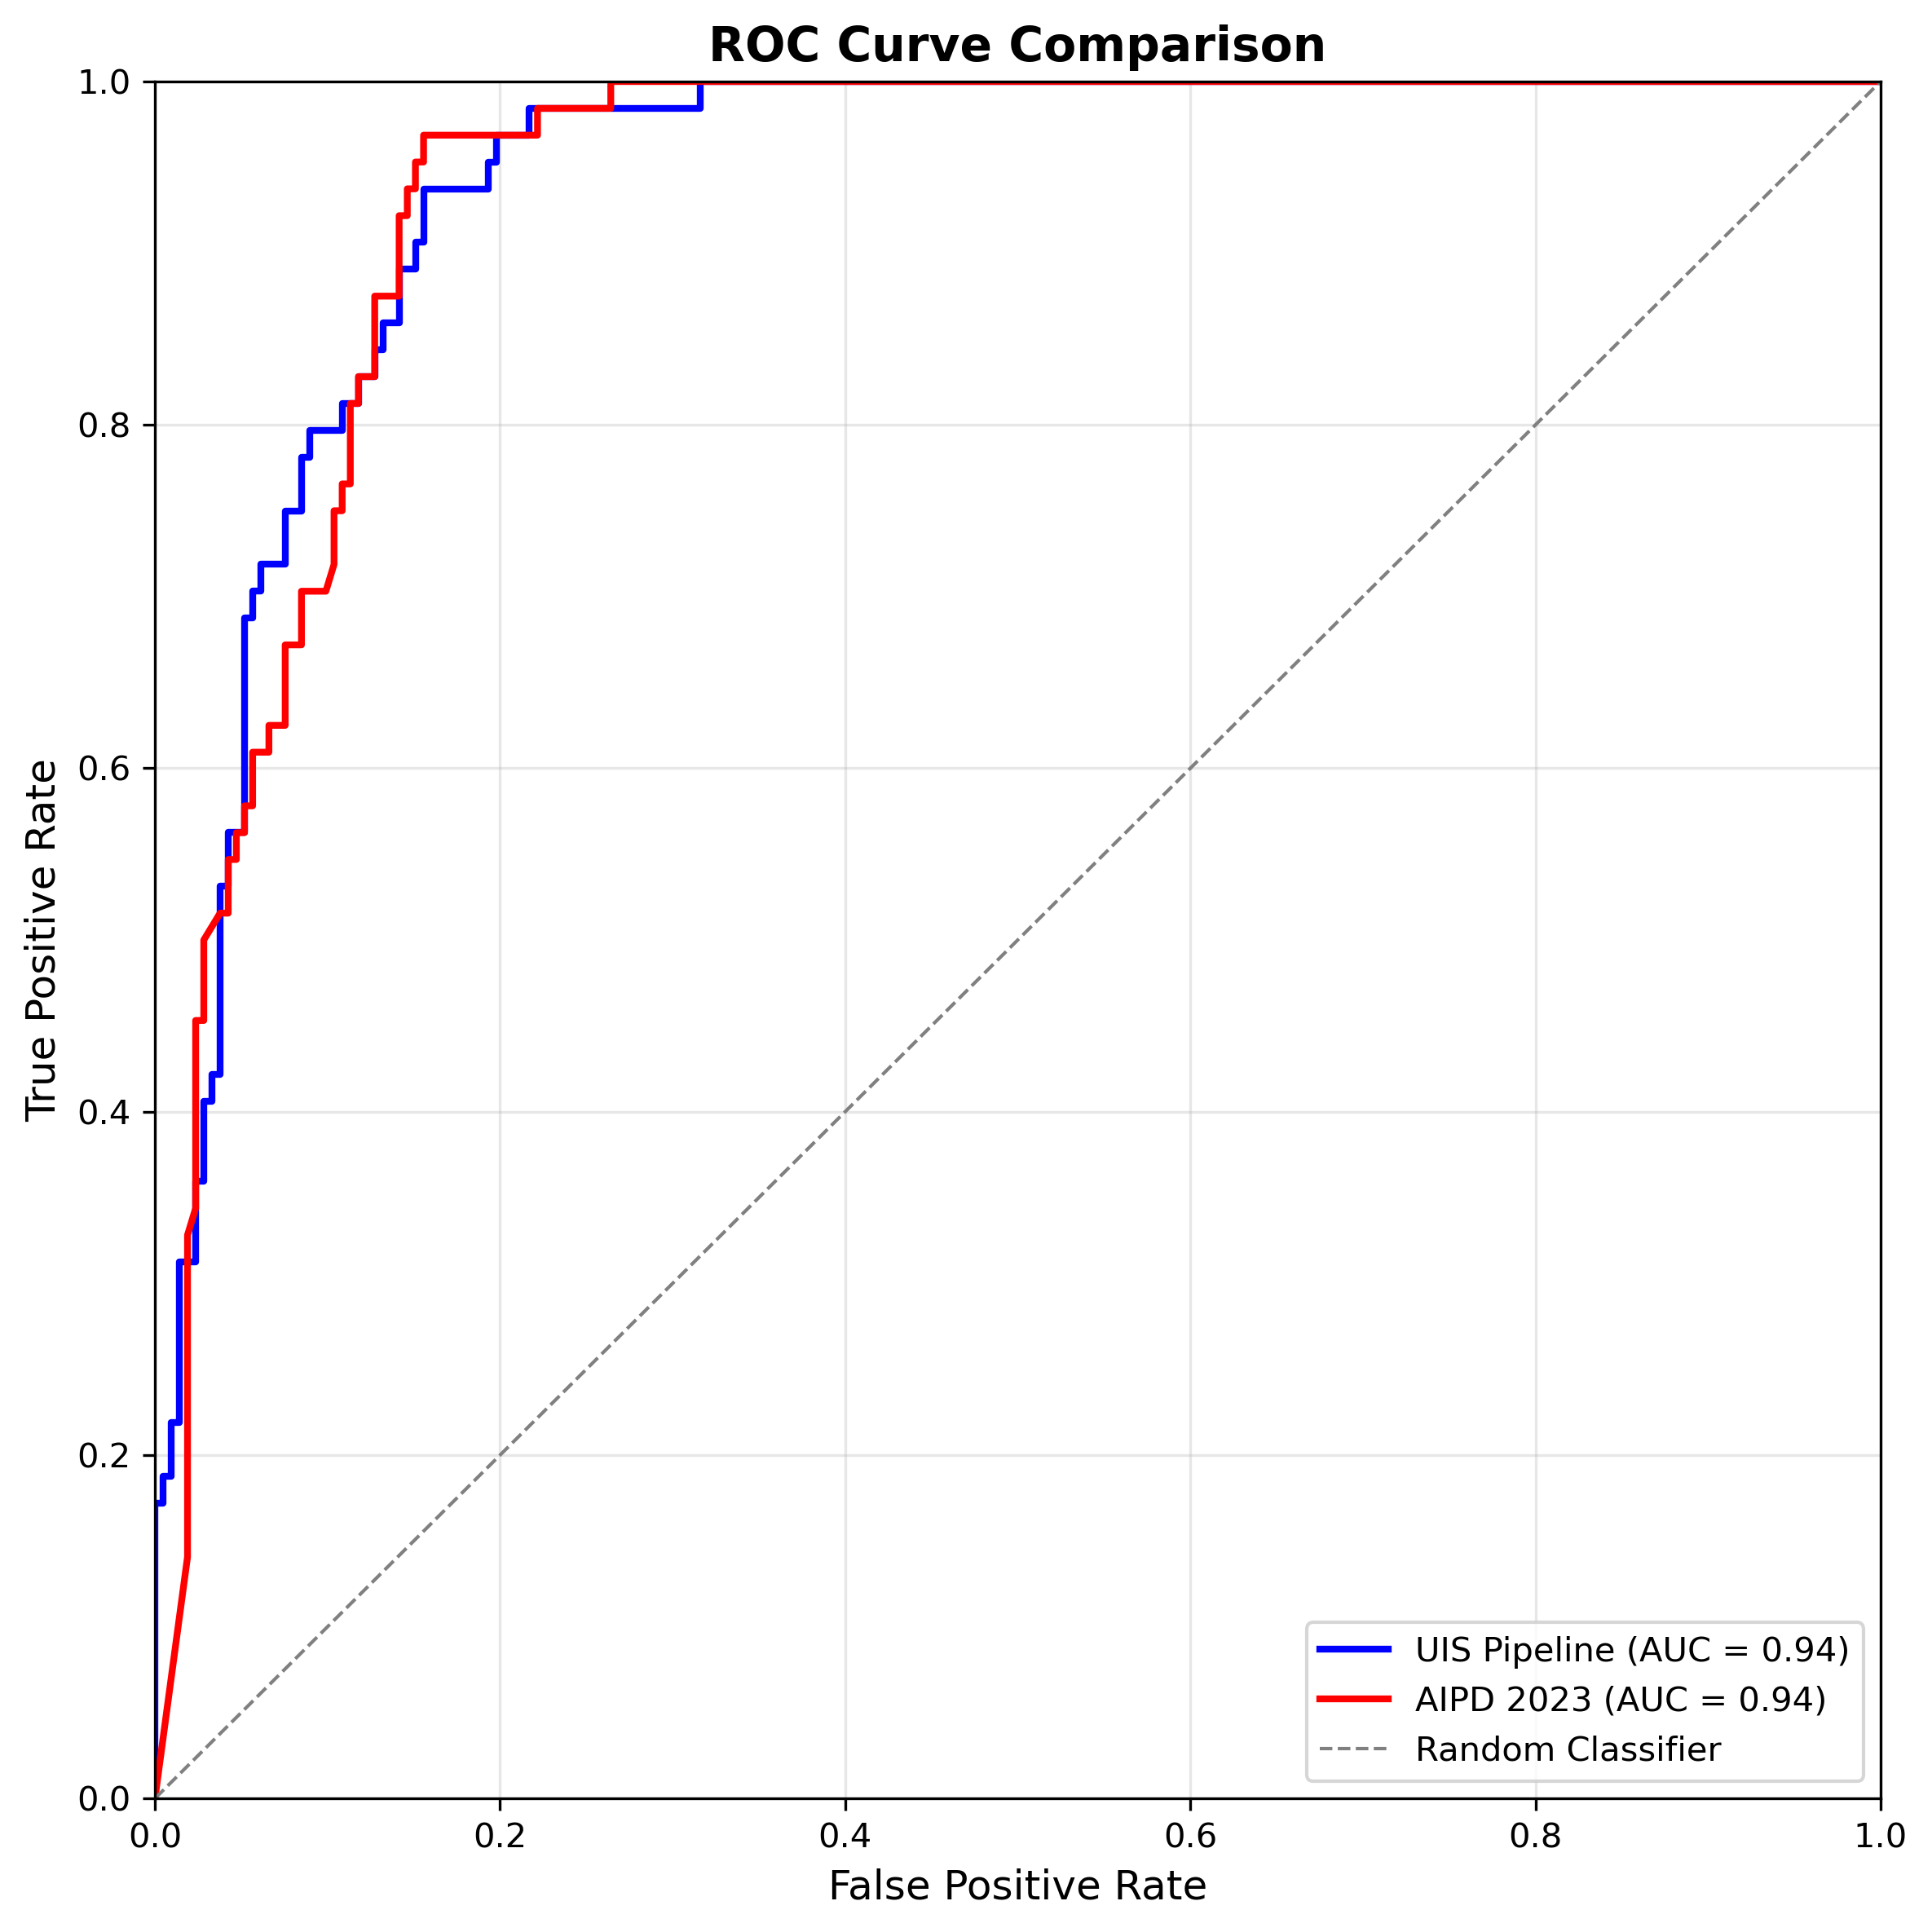

In [7]:
import pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC for Model 1 (e.g., BERT)
fpr1, tpr1, thresholds1 = roc_curve(y_true, y_scores_test)
roc_auc1 = roc_auc_score(y_true, y_scores_test)

# Calculate ROC for Model 2 (e.g., RoBERTa)
fpr2, tpr2, thresholds2 = roc_curve(y_true, y_scores_test1)
roc_auc2 = roc_auc_score(y_true, y_scores_test1)

# Create single plot
plt.figure(figsize=(8, 8), dpi=300)

# Plot both ROC curves on the same axes
plt.plot(fpr1, tpr1, color='blue', linewidth=2, label=f'UIS Pipeline (AUC = {roc_auc1:.2f})')
plt.plot(fpr2, tpr2, color='red', linewidth=2, label=f'AIPD 2023 (AUC = {roc_auc2:.2f})')

# Plot diagonal line (random classifier)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Random Classifier')

# Set limits and labels
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison', fontsize=14, fontweight='bold')

# Add legend and grid
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, alpha=0.3)

# Adjust layout and save
plt.tight_layout()
plt.savefig('./roc_curves_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# brier score for binary

In [7]:
llm

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,their_score_planning,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.923894,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.007498,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.530319,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.999981,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.001134,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.000004,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000116,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000207,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003473,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
their_work_binary_score = []
for id in llm['patent_id']:

    score_ng = []
    for name in name_groups:
        score_ng.append(llm[llm['patent_id']==id][f'their_score_{name}'].iloc[0])
    their_work_binary_score.append(max(score_ng))


In [4]:
from briertools import BrierScorer

y_true = list(llm["overall_ai_score"])
y_pred_our = list(llm["Our_work"])
y_pred_their = their_work_binary_score

brier_scorer = BrierScorer()
brier_score_our = brier_scorer.score(y_true, y_pred_our)
brier_score_their = brier_scorer.score(y_true, y_pred_their)

print('-------------')

print(f"Our brierscore: {brier_score_our}")
print(f"Their brierscore: {brier_score_their}")


-------------
Our brierscore: 0.12151449752482606
Their brierscore: 0.19550715590641304


# find CI with brier

In [12]:
import numpy as np

y_true = np.array(llm["overall_ai_score"])
y_pred_our = np.array(llm["Our_work"])
y_pred_their = np.array(their_work_binary_score)

def brier_score(y_true, y_pred):
    """Compute Brier score. Works for binary (0/1) or continuous [0,1] targets."""
    return np.mean((y_pred - y_true) ** 2)

def paired_bootstrap_brier(y_true, pred_uis, pred_aipd, n_bootstrap=5000, seed=42):
    np.random.seed(seed)
    n = len(y_true)
    diffs = np.empty(n_bootstrap)
    
    for b in range(n_bootstrap):
        idx = np.random.choice(n, size=n, replace=True)
        # print(idx)
        b_uis = brier_score(y_true[idx], pred_uis[idx])
        b_aipd = brier_score(y_true[idx], pred_aipd[idx])
        diffs[b] = b_uis - b_aipd  # Positive means UIS has lower (better) Brier
        
    ci_lower = np.percentile(diffs, 2.5)
    ci_upper = np.percentile(diffs, 97.5)
    mean_diff = np.mean(diffs)
    p_val = 2 * min(
    np.mean(diffs >= 0),  # Proportion of diffs ≥ 0
    np.mean(diffs <= 0)   # Proportion of diffs ≤ 0
    )  # Two-sided
    return mean_diff, (ci_lower, ci_upper), p_val

# Usage:
# y_true: LLM-derived relevance scores (continuous or thresholded binary)
# pred_uis: UIS predicted probabilities/scores
# pred_aipd: AIPD 2023 predicted probabilities/scores
mean_diff, ci, p_val = paired_bootstrap_brier(y_true, y_pred_our, y_pred_their)
print(f"Brier Diff (UIS - AIPD): {mean_diff:.4f} | 95% CI: [{ci[0]:.4f}, {ci[1]:.4f}] | p={p_val:.4f}")


Brier Diff (UIS - AIPD): -0.0741 | 95% CI: [-0.1022, -0.0461] | p=0.0000


In [21]:
import numpy as np
from sklearn.metrics import f1_score
from scipy.stats import norm
def paired_permutation_test_f1(y_true, y_pred1, y_pred2, n_perm=10000, random_state=42):
    """Paired permutation test for F1 score difference."""
    np.random.seed(random_state)
    f1_1 = f1_score(y_true, y_pred1)
    f1_2 = f1_score(y_true, y_pred2)
    obs_diff = f1_1 - f1_2
   
    n = len(y_true)
    # Vectorized permutation: flip predictions within each pair
    flips = np.random.choice([0, 1], size=(n_perm, n))
    p1 = np.where(flips == 0, y_pred1, y_pred2)
    p2 = np.where(flips == 1, y_pred1, y_pred2)
    perm_diffs = np.array([f1_score(y_true, p1[i]) - f1_score(y_true, p2[i])
                           for i in range(n_perm)])
   
    p_val = np.mean(np.abs(perm_diffs) >= np.abs(obs_diff))
    return p_val, obs_diff, perm_diffs

import numpy as np
from sklearn.metrics import f1_score
from scipy.stats import norm


def bca_bootstrap_ci_f1(
    y_true,
    y_pred1,
    y_pred2,
    n_boot=10000,
    alpha=0.05,
    random_state=42
):
    """
    BCa bootstrap confidence interval for the difference
    between two paired F1 scores.

    Difference = F1(pred1) - F1(pred2)
    """

    rng = np.random.default_rng(random_state)

    y_true = np.asarray(y_true)
    y_pred1 = np.asarray(y_pred1)
    y_pred2 = np.asarray(y_pred2)

    n = len(y_true)

    # --------------------------------------------------
    # 1. Observed F1 difference
    # --------------------------------------------------
    f1_1 = f1_score(y_true, y_pred1, zero_division=0)
    f1_2 = f1_score(y_true, y_pred2, zero_division=0)

    observed_diff = f1_1 - f1_2

    # --------------------------------------------------
    # 2. Bootstrap distribution
    # --------------------------------------------------
    boot_diffs = np.empty(n_boot)

    for i in range(n_boot):

        idx = rng.integers(0, n, size=n)

        boot_diffs[i] = (
            f1_score(
                y_true[idx],
                y_pred1[idx],
                zero_division=0
            )
            -
            f1_score(
                y_true[idx],
                y_pred2[idx],
                zero_division=0
            )
        )

    # --------------------------------------------------
    # 3. Bias correction z0
    # --------------------------------------------------
    # Proportion of bootstrap estimates below observed estimate
    prop_less = np.mean(boot_diffs < observed_diff)

    # Avoid norm.ppf(0) and norm.ppf(1)
    eps = 1 / (2 * n_boot)
    prop_less = np.clip(prop_less, eps, 1 - eps)

    z0 = norm.ppf(prop_less)

    # --------------------------------------------------
    # 4. Jackknife estimates
    # --------------------------------------------------
    jack_diffs = np.empty(n)

    for i in range(n):

        mask = np.ones(n, dtype=bool)
        mask[i] = False

        jack_diffs[i] = (
            f1_score(
                y_true[mask],
                y_pred1[mask],
                zero_division=0
            )
            -
            f1_score(
                y_true[mask],
                y_pred2[mask],
                zero_division=0
            )
        )

    # --------------------------------------------------
    # 5. Acceleration factor
    # --------------------------------------------------
    jack_mean = np.mean(jack_diffs)

    numerator = np.sum(
        (jack_mean - jack_diffs) ** 3
    )

    denominator = 6 * (
        np.sum(
            (jack_mean - jack_diffs) ** 2
        ) ** 1.5
    )

    if denominator == 0:
        acceleration = 0.0
    else:
        acceleration = numerator / denominator

    # --------------------------------------------------
    # 6. BCa adjusted probabilities
    # --------------------------------------------------
    z_alpha_low = norm.ppf(alpha / 2)
    z_alpha_high = norm.ppf(1 - alpha / 2)

    def bca_probability(z_alpha):

        numerator = z0 + z_alpha

        denominator = (
            1 - acceleration * numerator
        )

        return norm.cdf(
            z0 + numerator / denominator
        )

    p_low = bca_probability(z_alpha_low)
    p_high = bca_probability(z_alpha_high)

    # Make absolutely sure they are valid percentiles
    p_low = np.clip(p_low, 0, 1)
    p_high = np.clip(p_high, 0, 1)

    # --------------------------------------------------
    # 7. Confidence interval
    # --------------------------------------------------
    ci = np.percentile(
        boot_diffs,
        [p_low * 100, p_high * 100]
    )

    return ci, boot_diffs

# Example usage:
p_val, obs_diff, perm_diffs = paired_permutation_test_f1(np.array(y_true), np.array(y_pred1), np.array(y_pred2))
ci, boot_diffs = bca_bootstrap_ci_f1(np.array(y_true), np.array(y_pred1), np.array(y_pred2))
print(f"F1 diff: {obs_diff:.4f}, p={p_val:.4f}, 95% BCa CI: [{ci[0]:.4f}, {ci[1]:.4f}]")


F1 diff: 0.0953, p=0.0000, 95% BCa CI: [0.0490, 0.1422]


In [16]:
y_scores_test1

[0.0030815878,
 0.99999642,
 0.044742968,
 0.99680799,
 0.0052996948,
 0.99994385,
 1.0,
 0.99999523,
 0.0055730161,
 0.99997318,
 0.027152469,
 0.0052431668,
 0.08443477,
 0.99999726,
 0.013628551,
 0.0010575147,
 0.0018404557,
 0.0067832558,
 0.99997962,
 0.043168418,
 0.0069521228,
 0.030680431,
 0.005151283,
 0.0033951066,
 0.0015428088,
 0.99999011,
 1.0,
 0.016217085,
 0.0009443388,
 0.0014753065,
 0.99999976,
 0.013062194,
 0.023603562,
 0.0047310763,
 0.99999976,
 0.021549374,
 0.019004883,
 0.024362016,
 0.0018886791,
 0.0020774177,
 0.99995649,
 0.99999821,
 0.9996748,
 0.0041959849,
 0.01135857,
 0.00087732065,
 0.99999964,
 1.0,
 0.0011968161,
 0.99999523,
 0.99985743,
 0.058897555,
 1.0,
 0.0087869093,
 0.99999964,
 0.040714979,
 0.99985874,
 0.018479958,
 1.0,
 0.0016759521,
 0.00038842089,
 0.98057002,
 0.9999758,
 0.99999762,
 0.0279327,
 0.51243407,
 0.99869734,
 0.98258096,
 0.99996805,
 0.99999964,
 0.99957138,
 0.96983343,
 0.97865045,
 0.001231763,
 0.99999917,
 0.